# Partie 8: Analyse des résultats de variabilité

Dans cette section, nous analysons l'impact des différents facteurs de variabilité sur le pourcentage d'égalités mathématiques vérifiées lors des expérimentations.

## 1. Description des facteurs de variabilité et données d'expérimentation

Cette analyse repose sur les données d'exécution issues des étapes 6 et 7 de l'expérimentation, sérialisées dans deux fichiers CSV :
- [`../part6/results.csv`](../part6/results.csv) : Résultats des exécutions issues de l'expérimentation sur l'architecture locale.
- [`../part7/results.csv`](../part7/results.csv) : Résultats des exécutions réalisées via la matrice CI/CD de GitHub Actions intégrant les variations d'architecture CPU.

### Facteurs de variabilité étudiés :
- **Language** : Langage de programmation utilisé (`Python`, `Java`).
- **Environment (Env / Execution Environment)** : Environnement d'exécution (`CPython`, `PyPy` pour Python ; `OpenJDK`, `GraalVM` pour Java).
- **Property** : Propriété mathématique vérifiée (`Associativity` : `(x + y) + z == x + (y + z)`, `Distributivity` : `x * (y + z) == x * y + x * z`).
- **Repetitions** : Nombre de répétitions par test (`Tests100`, `Tests1000`, `Tests10_000`, `Tests100_000`, `Tests1_000_000`).
- **Interval** : Intervalle de génération des nombres aléatoires (`Interval01` : $[0, 1]$, `Interval1_000_000` : $[-1\,000\,000, 1\,000\,000]$).
- **Seed** : Graine d'initialisation du générateur pseudo-aléatoire (`Seed42`, `Seed152`).
- **NumericType / Precision** : Type numérique et précision binaire (`PythonFloat64` / `JavaDouble` pour la double précision 64-bit, `PythonFloat32` / `JavaFloat` pour la simple précision 32-bit).
- **RandomGenerator** : Algorithme de génération de nombres aléatoires (`PythonRandom`, `PythonNumPyRandom`, `JavaRandom`, `JavaSplittableRandom`).
- **Runner / CPU Architecture** (dans `part7/results.csv`) : Architecture d'exécution (`ubuntu-24.04` pour x86_64, `ubuntu-24.04-arm` pour ARM64).

### Statistiques de génération :
- **Nombre de configurations générées** : **33 configurations** uniques au total (dont les 3 programmes de référence `program1` représentant le programme écris manuellement, `program2` représentant celui généré par un LLM avec un language L2(ici Java), `program3`représentant celui généré aussi par un LLM(en Python) et 30 configurations échantillonnées via le variability model UVL).
- **Répétitions des exécutions** : Chaque configuration a été exécutée **3 fois** afin de contrôler la stabilité des résultats.
- **Taille totale des datasets** :
  - `part6/results.csv` contient **189 lignes** ($63 \text{ configurations} \times 3 \text{ exécutions}$).
  - `part7/results.csv` contient **198 lignes** ($63 \text{ configurations} \times 3 \text{ exécutions} \times 2 \text{ architectures CPU}$).
- **Colonne `results` dans les 2 fichiers CSV** : La valeur représente le **pourcentage d'égalités strictement vérifiées** ($\frac{\text{nombre d'égalités}}{\text{nombre de répétitions}} \times 100$) renvoyé par le programme exécuté.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn import tree

# Chargement des deux fichiers CSV de résultats
df_local = pd.read_csv('../part6/results.csv')
df_archi = pd.read_csv('../part7/results.csv')

print(f"Dimensions de part6/results.csv : {df_local.shape}")
print(f"Dimensions de part7/results.csv : {df_archi.shape}")
print(f"Nombre de configurations uniques : {df_local['config_id'].nunique()}")
print(f"Nombre d'exécutions par configuration : {df_local.groupby('config_id').size().iloc[0]}")

Dimensions de part6/results.csv : (189, 16)
Dimensions de part7/results.csv : (378, 17)
Nombre de configurations uniques : 63
Nombre d'exécutions par configuration : 3


## 2. Analyse préliminaire : Stabilité inter-exécutions et impact de l'architecture CPU

### Déviation entre exécutions identiques :
En comparant les 3 exécutions répétées pour chaque configuration unique, les résultats observés pour une configuration donnée ne montrent **aucune déviation** (écart-type égal à 0).

### Impact du changement d'architecture CPU (x86_64 vs ARM64) :
En comparant les résultats obtenus sous `ubuntu-24.04` (x86_64) et `ubuntu-24.04-arm` (ARM64) dans `part7/results.csv`, la différence absolue maximale enregistrée sur la colonne `results` est **strictement égale à 0.0%**.

**Conclusion préliminaire :** La modification de l'architecture processeur (x86_64 vs ARM64) et la répétition des exécutions dans le même environnement sans changer les valeurs des facteurs de variabilité, n'introduisent aucune variabilité. En effet, la représentation à la norme IEEE 754 des types 32 bits et 64 bits reste strictement identique entre ces deux architectures.

In [4]:
# 1. Vérification de la déviation entre exécutions pour une même configuration
std_per_config = df_local.groupby('config_id')['results'].std().fillna(0)
print(f"Écart-type maximum entre les 3 exécutions d'une même config : {std_per_config.max():.6f}")

# 2. Comparaison entre les deux architectures CPU dans resultswitharchi.csv
df_x86 = df_archi[df_archi['runner'] == 'ubuntu-24.04'].sort_values('config_id')['results'].values
df_arm = df_archi[df_archi['runner'] == 'ubuntu-24.04-arm'].sort_values('config_id')['results'].values

max_cpu_diff = np.max(np.abs(df_x86 - df_arm))
print(f"Différence absolue maximale entre x86_64 et ARM64 : {max_cpu_diff:.6f}%")

Écart-type maximum entre les 3 exécutions d'une même config : 0.000000
Différence absolue maximale entre x86_64 et ARM64 : 0.000000%


## 3. Analyse des facteurs de variabilité par comparaison ciblée (*Single-Factor Analysis*)

Pour isoler l'impact direct de chaque facteur de variabilité, nous sélectionnons les paires de configurations qui diffèrent par un seul et unique facteur, tous les autres facteurs étant maintenus strictement identiques.

In [5]:
# Normalisation des colonnes pour aligner Python et Java
def normalize_factors(df):
    data = df.copy()
    data['Execution Environment'] = data['Python'].fillna(data['Java'])
    data['Precision(32 or 64 bits)'] = data['PythonNumericType'].fillna(data['JavaNumericType']).str.replace('Python', '').str.replace('Java', '')
    data['RandomGenerator'] = data['PythonRandomGenerator'].fillna(data['JavaRandomGenerator']).str.replace('Python', '').str.replace('Java', '')
    return data

df_norm = normalize_factors(df_local)
config_df = df_norm.groupby('config_id').first().reset_index()

factor_cols = ['Language', 'Execution Environment', 'Property', 'Repetitions', 'Interval', 'Seed', 'Precision(32 or 64 bits)', 'RandomGenerator']

# Recherche des paires qui diffèrent par exactement 1 facteur
single_factor_pairs = []
for i in range(len(config_df)):
    for j in range(i+1, len(config_df)):
        c1, c2 = config_df.iloc[i], config_df.iloc[j]
        diffs = [f for f in factor_cols if c1[f] != c2[f]]
        if len(diffs) == 1:
            f = diffs[0]
            single_factor_pairs.append({
                'factor': f,
                'config1': c1['config_id'],
                'config2': c2['config_id'],
                'val1': c1[f],
                'val2': c2[f],
                'res1': c1['results'],
                'res2': c2['results'],
                'delta': abs(c1['results'] - c2['results'])
            })

df_pairs = pd.DataFrame(single_factor_pairs)
print("Statistiques des variations de résultats par facteur :")
print(df_pairs.groupby('factor')['delta'].agg(['count', 'mean', 'min', 'max']))

Statistiques des variations de résultats par facteur :
                          count       mean      min      max
factor                                                      
Execution Environment         6   0.000000   0.0000   0.0000
Interval                      5  10.544160   7.1753  14.0000
Precision(32 or 64 bits)      5  18.308380   7.5200  25.7608
Property                      4  14.790000  13.0000  17.0000
RandomGenerator               5   1.985320   0.0000   9.0000
Repetitions                  15   1.100153   0.0460   2.9280
Seed                          3   1.018600   0.0180   3.0000


### Interprétation des résultats par facteur de variabilité :

1. **Environment d'éxecution (`CPython`vs `PyPy`, `OpenJDK` vs`GraalVM`)** : **Aucune variabilité observée (Écart = 0.0%)** 
   -  Les comparaisons entre CPython et PyPy, ainsi qu'entre OpenJDK et GraalVM, ne montrent aucune différence de résultat lorsque les autres paramètres sont identiques. Dans les configurations testées, le choix de l'implémentation du langage ou de la JVM ne semble donc pas modifier les résultats obtenus.

2. **Interval (`Interval01` vs `Interval1_000_000`)** : **Provoque une variabilité modérée à forte (Écart moyen ~ 10.54%)**
   - Étendre l'intervalle des nombres générés à $[-1\,000\,000, 1\,000\,000]$ modifie significativement la répartition des exposants IEEE 754.

3. **Precision (`Float32` / `Float` vs `Float64` / `Double`)** : **Provoque une forte variabilité (Écart moyen ~ 18.3%)**
   - Passer de 64 bits (double) à 32 bits (float) réduit drastiquement le pourcentage de réussite des propriétés (ex: chute de ~?% à ~?% sur l'associativité).

4. **Property (`Associativity` vs `Distributivity`)** : **Provoque une forte variabilité (Écart ~ 14.79%)**
   - La distributivité ($x \times (y + z) == x \times y + x \times z$) échoue beaucoup plus fréquemment que l'associativité ($ (x + y) + z == x + (y + z) $).

5. **RandomGenerator (`Random` vs `NumPyRandom` / `SplittableRandom`)** : **Provoque une variabilité faible (Écart ~ 1.9%)**
   - Les différents algorithmes de génération pseudo-aléatoire fournissent des distributions de valeurs légèrement différentes.
6. **Repetitions** : **Faible impact (Écart ~ 1.1%)**
   - Varier le nombre d'échantillons (de 100 à 1 000 000) stabilise la valeur statistique vers sa moyenne.

7. **Seed faible variabilité (écart ~ 1,02%)**
   -  La graine aléatoire détermine la séquence de nombres générés par le générateur pseudo-aléatoire. Les différences observées entre les configurations utilisant des graines différentes restent faibles. Cela suggère que, dans les expériences réalisées, le choix de la graine a une influence limitée sur le résultat global.



## 4. Arbre de décision 

Pour modéliser hiérarchiquement l'impact global de chaque facteur sur le taux d'égalité obtenu (`results`), nous construisons un arbre de décision de régression (`DecisionTreeRegressor`).

--- Arbre de décision (représentation textuelle) ---
|--- Property_Distributivity <= 0.50
|   |--- Precision(32 or 64 bits)_Float <= 0.50
|   |   |--- Interval_Interval01 <= 0.50
|   |   |   |--- value: [91.93]
|   |   |--- Interval_Interval01 >  0.50
|   |   |   |--- value: [81.28]
|   |--- Precision(32 or 64 bits)_Float >  0.50
|   |   |--- Interval_Interval01 <= 0.50
|   |   |   |--- value: [66.18]
|   |   |--- Interval_Interval01 >  0.50
|   |   |   |--- value: [74.76]
|--- Property_Distributivity >  0.50
|   |--- Interval_Interval01 <= 0.50
|   |   |--- Precision(32 or 64 bits)_Double <= 0.50
|   |   |   |--- value: [53.95]
|   |   |--- Precision(32 or 64 bits)_Double >  0.50
|   |   |   |--- value: [58.49]
|   |--- Interval_Interval01 >  0.50
|   |   |--- Repetitions_Tests1000 <= 0.50
|   |   |   |--- value: [66.21]
|   |   |--- Repetitions_Tests1000 >  0.50
|   |   |   |--- value: [68.90]


--- Importance des facteurs ---
Property_Distributivity            0.611649
Precision(32 

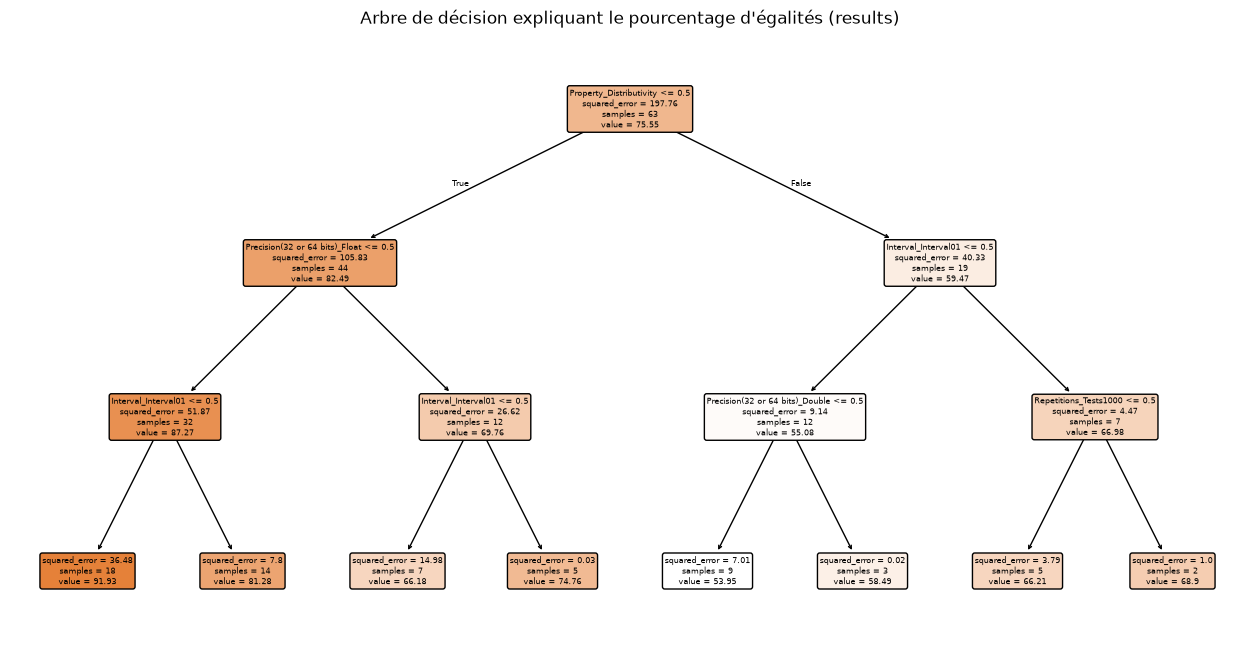

In [6]:
# Préparation des données explicatives
X = pd.get_dummies(config_df[['Language', 'Execution Environment', 'Property', 'Repetitions', 'Interval', 'Seed', 'Precision(32 or 64 bits)', 'RandomGenerator']], drop_first=False)
y = config_df['results']

# Entraînement de l'arbre de décision
dt = DecisionTreeRegressor(max_depth=3, random_state=42)
dt.fit(X, y)

# Affichage sous forme de texte
print("--- Arbre de décision (représentation textuelle) ---")
print(export_text(dt, feature_names=list(X.columns)))

# Importance des facteurs
importances = pd.Series(dt.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\n--- Importance des facteurs ---")
print(importances[importances > 0])

# Visualisation graphique de l'arbre
plt.figure(figsize=(16, 8))
tree.plot_tree(dt, feature_names=X.columns, filled=True, rounded=True, precision=2)
plt.title("Arbre de décision expliquant le pourcentage d'égalités (results)")
plt.show()

Cet arbre de décision permet de visualiser les facteurs qui contribuent à expliquer les variations des résultats, ainsi que leurs combinaisons. Il est construit à partir des 63 configurations de la partie 6 et cherche à regrouper celles qui présentent des résultats similaires.

**1. La propriété mathématique est le premier facteur de séparation. La première séparation concerne la propriété testée :**

- Associativity : 44 configurations, avec un résultat moyen de 82,49%.
- Distributivity : 19 configurations, avec un résultat moyen de 59,47%.

On observe donc une différence de 23,02% entre les deux groupes. La distributivité présente globalement des résultats nettement plus faibles que l'associativité.

**2. Pour l'associativité, la précision numérique joue un rôle important. Parmi les 44 configurations testant l'associativité, l'arbre effectue une séparation selon la précision :**

- Double (64 bits) : 32 configurations, avec un résultat moyen de 87,27.
- Float (32 bits) : 12 configurations, avec un résultat moyen de 69,76.

La différence entre ces deux groupes est de 17,51%. Les configurations utilisant une précision de 64 bits obtiennent donc de meilleurs résultats en moyenne.

&#x20; L'arbre affine ensuite ces groupes en fonction de l'intervalle de génération des nombres :

- En Double, le résultat moyen est de 91,93% pour l'intervalle `Interval1_000_000` (18 configurations), contre 81,28% pour `Interval01` (14 configurations).
- En Float, le résultat moyen est de 66,18% pour `Interval1_000_000` (7 configurations), contre 74,76% pour `Interval01` (5 configurations).

&#x20; Ces résultats montrent que l'effet de l'intervalle dépend également de la précision utilisée.

**3.  Pour la distributivité, l'intervalle est le premier facteur de séparation.**

&#x20; Parmi les 19 configurations testant la distributivité, l'arbre distingue d'abord les intervalles :

- Interval1_000_000 : 12 configurations, avec un résultat moyen de 55,08%.
- Interval01 : 7 configurations, avec un résultat moyen de 66,98%.

La différence entre les deux groupes est de 11,90%. Dans cet ensemble de configurations, l'intervalle plus large est associé à des résultats plus faibles.

&#x20; L'arbre affine ensuite ces groupes :

- Pour `Interval1_000_000`, il distingue les configurations en Double (3 configurations, résultat moyen de 58,49) et en Float (9 configurations, résultat moyen de 53,95).
- Pour `Interval01`, il utilise le nombre de répétitions : les configurations avec `Tests1000` (2 configurations) obtiennent un résultat moyen de 68,90, contre 66,21 pour les 5 autres configurations.

**4. Les autres facteurs ont une influence limitée dans les séparations de cet arbre.**

Les facteurs comme le générateur aléatoire (`RandomGenerator`), la graine (`Seed`) et l'environnement d'exécution ne sont pas utilisés dans les séparations représentées, en raison de leur faible influence par rapport aux autres facteurs, mais aussi afin de conserver un arbre lisible.

&#x20; Le nombre de répétitions intervient uniquement dans la dernière séparation de la branche associée à la distributivité, avec des résultats moyens de 66,21 et 68,90. Son influence semble donc plus limitée que celle de la propriété, de la précision et de l'intervalle dans cet arbre.

**5. Conclusion :**

&#x20; L'arbre de décision confirme globalement les observations de l'analyse par paires. La propriété mathématique testée est le facteur qui différencie le plus les résultats, suivie de la précision numérique et de l'intervalle de génération des nombres.

&#x20; Il met également en évidence que l'influence d'un facteur peut dépendre des autres paramètres. Par exemple, pour l'associativité, l'intervalle n'a pas le même effet selon que les calculs utilisent Float ou Double. Pour la distributivité, l'intervalle constitue au contraire le premier facteur de séparation.

&#x20; Ces résultats restent descriptifs : ils montrent les tendances présentes dans les 63 configurations étudiées, sans démontrer à eux seuls une relation de causalité.

## 5. Causalité des facteurs de variabilité

D'après les résultats obtenus avec l'arbre de décision présenté précédemment, la précision numérique (32 bits ou 64 bits) et l'intervalle des nombres semblent être deux facteurs ayant une influence importante sur les résultats, indépendamment des autres facteurs. Afin d'étudier leur causalité, nous avons repris notre modèle de variabilité UVL et créé deux modèles spécifiques, dans lesquels tous les facteurs sont fixés à l'exception de celui étudié.

Le premier modèle, [`numeric_precision_causality.uvl`](numeric_precision_causality.uvl), permet d'étudier l'influence de la précision numérique. Il a permis de générer les configurations [`numeric_precision_causality.csv`](numeric_precision_causality.csv), dont les résultats sont enregistrés dans [`numeric_precision_causality_results.csv`](numeric_precision_causality_results.csv).

Le second modèle, [`interval_causality.uvl`](interval_causality.uvl), permet d'étudier l'influence de l'intervalle des nombres. Les configurations générées sont enregistrées dans [`interval_causality.csv`](interval_causality.csv), et leurs résultats dans [`interval_causality_results.csv`](interval_causality_results.csv).

### 5.1 Influence de la précision numérique

Dans cette expérience, tous les facteurs sont identiques : CPython, associativité, 100 000 répétitions, intervalle [0,1], seed 42 et générateur PythonRandom. Seule la précision numérique varie.

Les résultats montrent que Float64 obtient un taux d'associativité de **82,759 %**, contre **74,616 %** pour Float32, soit un écart de **8,143 %**.

Cette différence s'explique par les mécanismes d'arrondi de l'arithmétique flottante : Float32 dispose d'une précision moindre que Float64, ce qui entraîne des erreurs d'arrondi plus importantes lors des opérations intermédiaires. L'expérience contrôlée met ainsi en évidence l'influence de la précision numérique sur le taux d'égalités vérifiées.

### 5.2 Influence de l'intervalle numérique

Dans cette deuxième expérience, tous les facteurs sont également fixés, à l'exception de l'intervalle des nombres. La précision utilisée est Float64.

Les résultats montrent un taux d'associativité de **82,759 %** pour l'intervalle [0,1], contre **92,979 %** pour l'intervalle [-1 000 000, 1 000 000], soit une augmentation de **10,22 %**.

Cette différence montre que la magnitude des nombres générés influence le comportement des opérations flottantes et leurs erreurs d'arrondi. Ainsi, même en conservant le même type numérique, modifier l'intervalle peut modifier significativement la proportion d'égalités vérifiées.

Voici une version corrigée, avec un français plus naturel, une meilleure fluidité et un format Markdown propre. J'ai conservé ton raisonnement et ton style d'écriture.

## 6. Analyse des résultats des labs #1 et #2

| Facteur de variabilité    | Programme écrit à la main (lab #1) | Programme généré par le LLM en Java (lab #2) | Programme généré par le LLM en Python (lab #3) |
| ------------------------- | ---------------------------------- | -------------------------------------------- | ---------------------------------------------- |
| Language                  | Python                             | Java                                         | Python                                         |
| Execution Environment     | CPython 3.12.3                     | OpenJDK 21.0.11                              | CPython 3.12.3                                 |
| Property                  | Associativity                      | Associativity                                | Associativity                                  |
| Repetitions               | 1 000                              | 1 000 000                                    | 1 000                                          |
| Interval                  | [0, 1]                             | [-1 000 000, 1 000 000]                      | [0, 1]                                         |
| Seed                      | 152                                | 42                                           | 42                                             |
| NumericType / Precision   | `float` (64 bits)                  | `double` (64 bits)                           | `float` (64 bits)                              |
| RandomGenerator           | `random.Random`                    | `java.util.Random`                           | `random.Random`                                |
| Résultat (taux d'égalité) | 82,50 %                            | 93,0671 %                                    | 82,00 %                                        |

Comme montré dans les parties 4 et 5, les facteurs de variabilité qui ont le plus d'influence sur les résultats sont la précision numérique et l'intervalle d'étude. En comparant les résultats des labs #1 et #2, la différence observée semble principalement liée à l'intervalle utilisé : [0, 1] au lab #1 et [-1 000 000, 1 000 000] au lab #2.

D'ailleurs, dans `../part6/results.csv`, on trouve les résultats de deux configurations similaires à celles des labs #1 et #2, mais avec un million de répétitions et des intervalles identiques à ceux des expériences correspondantes. Les lignes concernées sont les suivantes :

r40,random,Python,CPython,,Associativity,Tests1_000_000,Interval1_000_000,Seed152,PythonNumericType,PythonFloat64,,PythonRandomGenerator,,PythonRandom,93.054
r60,random,Java,,OpenJDK,Associativity,Tests1_000_000,Interval1_000_000,Seed42,JavaNumericType,,JavaDouble,JavaRandomGenerator,JavaSplittableRandom,,93.0538


Ces résultats confirment que l'intervalle est un facteur de variabilité important et expliquent en grande partie la différence observée entre les labs #1 et #2.

Concernant la faible différence de 0,5 point de pourcentage entre les labs #1 et #3, elle peut notamment s'expliquer par le choix de la seed, qui entraîne la génération de séquences de nombres différentes.


## 7. Impact des facteurs et recommandations

D'après les analyses réalisées, les facteurs qui font le plus varier les résultats sont la propriété testée, la précision numérique et l'intervalle. Le nombre de répétitions, la seed et le générateur aléatoire ont un impact plus limité. En revanche, aucune variation n'a été observée entre les environnements d'exécution et les architectures CPU comparés, lorsque les autres paramètres sont identiques.

Pour obtenir des résultats stables et comparables, voici les recommandations :

| Paramètres                                      | Recommandation                                                                                                                              |
| ----------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------- |
| À fixer                                         | La propriété, la précision, l'intervalle et le nombre de répétitions (idéalement 1 000 000).                                                |
| À fixer pour reproduire exactement l'expérience | La seed et le générateur aléatoire.                                                                                                         |
| Pas nécessairement à fixer                      | Le langage, l'environnement d'exécution et l'architecture CPU, puisqu'aucune différence n'a été observée dans les configurations comparées. |

Ainsi, les paramètres les plus importants à contrôler sont ceux qui influencent directement le calcul et les conditions de l'expérience. Les autres peuvent être laissés variables, sauf si l'objectif est de reproduire exactement une exécution.